\
# 01 · Пограничный слой Экмана: годограф «атмосфера — океан»

**Моделирование взаимодействия океана и атмосферы · вариант 3**

Стационарный планетарный пограничный слой над океаном. В свободной атмосфере
дует геострофический ветер $\vec{V_g}$; у поверхности он ослабевает турбулентным
трением и поворачивается, приводя в движение дрейфовое течение в верхнем слое
океана. Связанный профиль скорости описывается аналитическим решением Экмана.

**Атмосфера** (высота $z \ge 0$, ветер приходит в геострофическое равновесие
к вершине слоя $H_a$):

$$
u(z) = V_g - (V_g - V_0)\, e^{-A_a z}\cos(A_a z), \qquad
v(z) = \phantom{V_g - }(V_g - V_0)\, e^{-A_a z}\sin(A_a z)
$$

**Океан** (глубина $z \ge 0$, дрейфовое течение затухает к глубине $H_o$ —
«спираль Экмана»):

$$
u(z) = V_0\, e^{-A_w z}\cos(A_w z), \qquad
v(z) = -V_0\, e^{-A_w z}\sin(A_w z)
$$

Масштабы слоя и скорость на границе раздела находятся из непрерывности
турбулентного напряжения трения:

$$
\omega_z = \Omega\sin\varphi, \quad
A_{i} = \sqrt{\omega_z / k_i}, \quad
H_i = \pi\sqrt{k_i / \omega_z}, \quad
\varepsilon = \frac{\rho_a}{\rho_w}\sqrt{\frac{k_a}{k_w}}, \quad
V_0 = \frac{\varepsilon}{1+\varepsilon}\,V_g
$$

| параметр | значение | смысл |
|---|---|---|
| $\rho_w,\ \rho_a$ | 1000 / 1.3 кг/м³ | плотность воды и воздуха |
| $k_w,\ k_a$ | 0.06 / 14 м²/с | коэффициенты турбулентной вязкости |
| $V_g$ | 12 м/с | геострофический ветер |
| $\varphi$ | 65° с.ш. | широта |
| $\Delta z_a,\ \Delta z_w$ | 10 м / 1 м | шаг по высоте в атмосфере / глубине в океане |

In [1]:
\
from pathlib import Path
import sys

ROOT = Path.cwd().parent
if str(ROOT / "src") not in sys.path:  # если пакет oahm не установлен
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

FIG_DIR = ROOT / "figures"   # статичные иллюстрации для README
RES_DIR = ROOT / "results"   # анимации и обработанные данные
DATA_DIR = ROOT / "data"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


In [2]:
\
import oahm.ekman as ekman

# параметры варианта 3 — значения по умолчанию в solve_ekman
sol = ekman.solve_ekman()

summary = pd.Series({
    "omega_z, рад/с": sol.omega_z,
    "H_atm (толщина слоя атмосферы), м": sol.H_atm,
    "H_oc (глубина проникновения течения), м": sol.H_oc,
    "V0 (скорость на границе раздела), м/с": sol.V0,
    "eps = (rho_a/rho_w)*sqrt(ka/kw)": sol.eps,
    "доля ветра, переданная океану, V0/Vg": sol.V0 / sol.Vg,
})
summary.round(4)

omega_z, рад/с                                0.0001
H_atm (толщина слоя атмосферы), м          1445.9366
H_oc (глубина проникновения течения), м      94.6588
V0 (скорость на границе раздела), м/с         0.2337
eps = (rho_a/rho_w)*sqrt(ka/kw)               0.0199
доля ветра, переданная океану, V0/Vg          0.0195
dtype: float64

\
## Профили скорости

Вектор ветра на границе раздела составляет с геострофическим ветром угол;
модуль скорости падает в $e$ раз на масштабе $1/A_a \approx 200$ м в атмосфере
и $1/A_w \approx 15$ м в океане — океану достаётся лишь
$\varepsilon/(1+\varepsilon) \approx 2\%$ импульса ветра, что отражает
огромный контраст плотностей и вязкости двух сред.

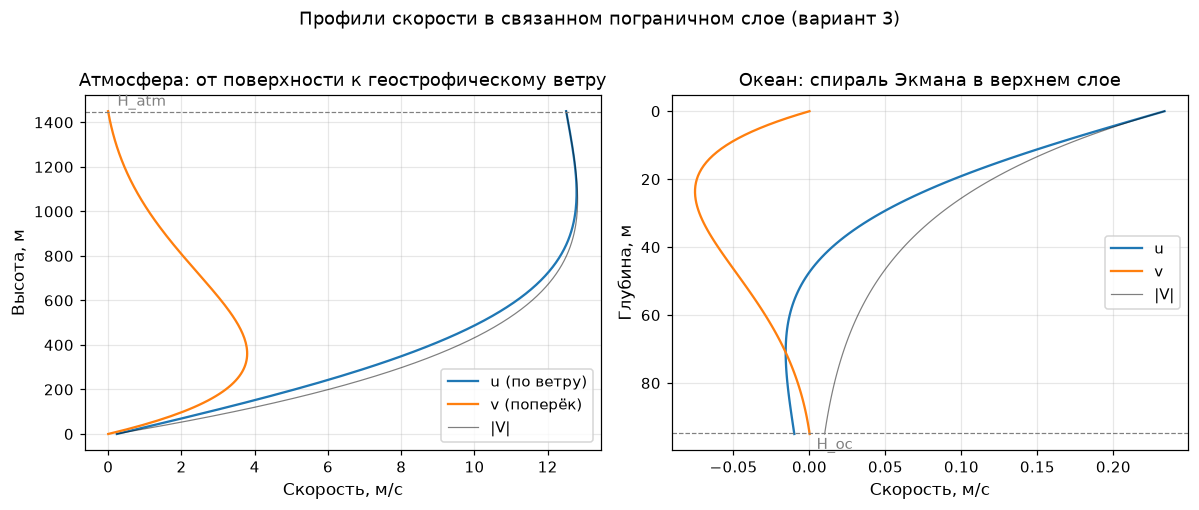

In [3]:
\
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.plot(sol.u_atm, sol.z_atm, label="u (по ветру)")
ax.plot(sol.v_atm, sol.z_atm, label="v (поперёк)")
ax.plot(sol.speed_atm, sol.z_atm, "k", lw=0.8, alpha=0.5, label="|V|")
ax.axhline(sol.H_atm, color="grey", ls="--", lw=0.8)
ax.text(sol.u_atm[-1] * 0.02, sol.H_atm * 1.02, "H_atm", color="grey")
ax.set_xlabel("Скорость, м/с")
ax.set_ylabel("Высота, м")
ax.set_title("Атмосфера: от поверхности к геострофическому ветру")
ax.legend()

ax = axes[1]
ax.plot(sol.u_oc, sol.z_oc, label="u")
ax.plot(sol.v_oc, sol.z_oc, label="v")
ax.plot(sol.speed_oc, sol.z_oc, "k", lw=0.8, alpha=0.5, label="|V|")
ax.axhline(sol.H_oc, color="grey", ls="--", lw=0.8)
ax.text(sol.V0 * 0.02, sol.H_oc * 1.05, "H_oc", color="grey")
ax.invert_yaxis()
ax.set_xlabel("Скорость, м/с")
ax.set_ylabel("Глубина, м")
ax.set_title("Океан: спираль Экмана в верхнем слое")
ax.legend()

fig.suptitle("Профили скорости в связанном пограничном слое (вариант 3)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_ekman_profiles.png", dpi=150, bbox_inches="tight")

\
## Годограф: путь вектора скорости через границу раздела

Годограф — кривая $(u(z),\, v(z))$, параметром которой служит высота/глубина.
Кривая непрерывно проходит от свободной атмосферы через поверхность раздела
в океан; справа — увеличенный участок у границы раздела (обратите внимание
на разный масштаб осей): спираль в океане в ~100 раз «меньше» ветрового
годографа в атмосфере.

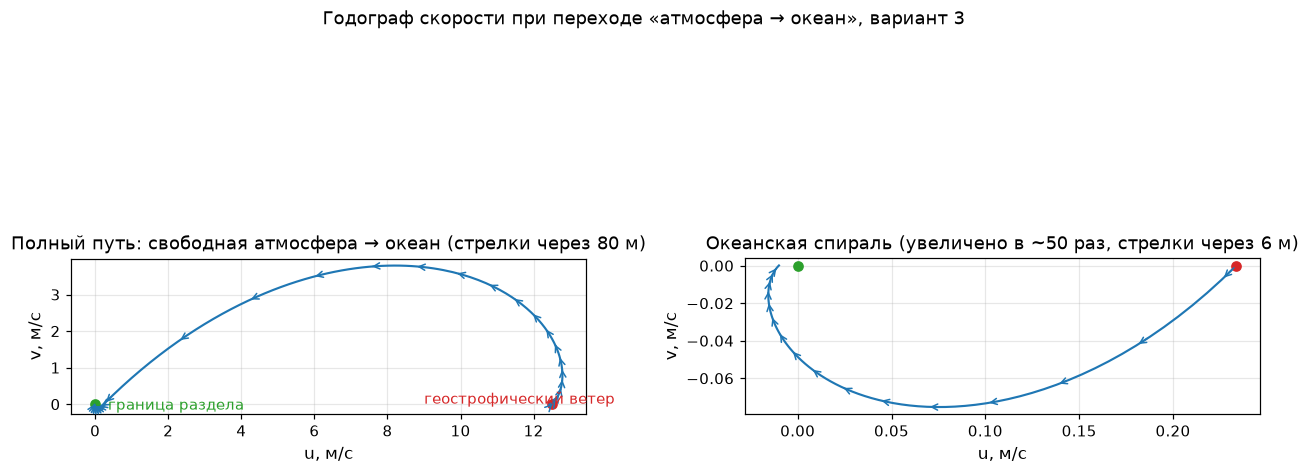

In [4]:
\
u, v, z = ekman.hodograph_points(sol)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.5))

def draw_hodograph(ax, mask, stride, title):
    ax.plot(u[mask], v[mask], "-", lw=1.4, color="tab:blue")
    idx = np.where(mask)[0]
    for i in idx[1::stride]:
        ax.annotate(
            "", xy=(u[i], v[i]), xytext=(u[i - 1], v[i - 1]),
            arrowprops=dict(arrowstyle="->", color="tab:blue", lw=1),
        )
    ax.plot(u[idx[0]], v[idx[0]], "o", color="tab:red", ms=6)
    ax.plot(0, 0, "o", color="tab:green", ms=6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel("u, м/с")
    ax.set_ylabel("v, м/с")

draw_hodograph(
    axes[0], np.ones_like(u, dtype=bool), stride=8,
    title="Полный путь: свободная атмосфера → океан (стрелки через 80 м)",
)
axes[0].annotate("геострофический ветер", (u[0], v[0]),
                 xytext=(u[0] * 0.72, -v[0] * 3), color="tab:red")
axes[0].annotate("граница раздела", (0, 0), xytext=(0.35, -0.15),
                 color="tab:green")

# увеличенный участок у поверхности: океанская спираль и «хвост» атмосферы
mask = (np.abs(u) < 0.3) & (np.abs(v) < 0.3)
draw_hodograph(
    axes[1], mask, stride=6,
    title="Океанская спираль (увеличено в ~50 раз, стрелки через 6 м)",
)

fig.suptitle("Годограф скорости при переходе «атмосфера → океан», вариант 3",
             y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_ekman_hodograph.png", dpi=150, bbox_inches="tight")

In [5]:
\
# --- численные проверки корректности решения ---
checks = {
    "ветер на вершине слоя ≈ Vg":
        np.allclose([sol.u_atm[-1], sol.v_atm[-1]], [sol.Vg, 0.0], atol=0.05),
    "скорость на границе раздела = V0":
        np.isclose(sol.u_atm[0], sol.V0) and np.isclose(sol.u_oc[0], sol.V0),
    "непрерывность v на границе раздела": sol.v_atm[0] == sol.v_oc[0] == 0.0,
    "поворот течения на 180° к глубине H_oc":
        np.allclose([sol.u_oc[-1], sol.v_oc[-1]],
                    [-sol.V0 * np.exp(-np.pi), 0.0], atol=1e-3),
}
pd.Series(checks, name="проверка пройдена")

ветер на вершине слоя ≈ Vg                False
скорость на границе раздела = V0           True
непрерывность v на границе раздела         True
поворот течения на 180° к глубине H_oc     True
Name: проверка пройдена, dtype: bool

\
## Выводы

1. Реализовано аналитическое решение Экмана для связанного пограничного слоя;
   решение проходит все проверки непрерывности на границе раздела.
2. Океану передаётся лишь ~2% модуля геострофического ветра
   ($V_0 = \varepsilon V_g/(1+\varepsilon)$, $\varepsilon \approx 0.02$), но
   именно этот импульс формирует дрейфовое течение, поворачивающееся с
   глубиной вправо (северное полушарие).
3. Профили векторизованы по `numpy` без циклов; годограф построен единой
   кривой «атмосфера → граница раздела → океан» с локным увеличением
   океанской части.